# Statistical Analysis of Road Collisions in 2025

## 1. Data Loading and Inspection

In [1]:
import pandas as pd

df=pd.read_csv("road-2025.csv")


In [2]:
df.head()

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
0,202517M101925,2025,17M101925,447673.0,519279.0,-1.26420,54.56650,17,3,1,...,-1,0,1,1,2,E01012014,3,1,0.0,1.0
1,202517L205225,2025,17L205225,454611.0,518597.0,-1.15704,54.55967,17,3,2,...,-1,0,1,1,2,E01012173,3,1,0.0,1.0
2,2025070971700,2025,070971700,354476.0,382656.0,-2.68516,53.33884,7,3,2,...,-1,0,2,1,2,E01012444,3,1,0.0,1.0
3,2025070403274,2025,070403274,361793.0,393163.0,-2.57655,53.43386,7,3,2,...,-1,0,2,3,2,E01012468,3,1,0.0,1.0
4,2025071000604,2025,071000604,366083.0,389327.0,-2.51157,53.39967,7,3,7,...,-1,0,2,1,1,E01012551,3,1,0.0,1.0


In [3]:
df.shape

(101525, 44)

In [4]:
print("df:")
print(df.isnull().sum())

df:
collision_index                                     0
collision_year                                      0
collision_ref_no                                    0
location_easting_osgr                               2
location_northing_osgr                              2
longitude                                           2
latitude                                            2
police_force                                        0
collision_severity                                  0
number_of_vehicles                                  0
number_of_casualties                                0
date                                                0
day_of_week                                         0
time                                                0
local_authority_district                            0
local_authority_ons_district                        0
local_authority_highway                             0
local_authority_highway_current                     0
first_road_class        

In [5]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101525 entries, 0 to 101524
Data columns (total 44 columns):
 #   Column                                            Non-Null Count   Dtype  
---  ------                                            --------------   -----  
 0   collision_index                                   101525 non-null  object 
 1   collision_year                                    101525 non-null  int64  
 2   collision_ref_no                                  101525 non-null  object 
 3   location_easting_osgr                             101523 non-null  float64
 4   location_northing_osgr                            101523 non-null  float64
 5   longitude                                         101523 non-null  float64
 6   latitude                                          101523 non-null  float64
 7   police_force                                      101525 non-null  int64  
 8   collision_severity                                101525 non-null  int64  
 9   numb

In [6]:
print("df:",df.duplicated().sum())

df: 0


In [7]:

print(df.columns)

Index(['collision_index', 'collision_year', 'collision_ref_no',
       'location_easting_osgr', 'location_northing_osgr', 'longitude',
       'latitude', 'police_force', 'collision_severity', 'number_of_vehicles',
       'number_of_casualties', 'date', 'day_of_week', 'time',
       'local_authority_district', 'local_authority_ons_district',
       'local_authority_highway', 'local_authority_highway_current',
       'first_road_class', 'first_road_number', 'road_type', 'speed_limit',
       'junction_detail_historic', 'junction_detail', 'junction_control',
       'second_road_class', 'second_road_number',
       'pedestrian_crossing_human_control_historic',
       'pedestrian_crossing_physical_facilities_historic',
       'pedestrian_crossing', 'light_conditions', 'weather_conditions',
       'road_surface_conditions', 'special_conditions_at_site',
       'carriageway_hazards_historic', 'carriageway_hazards',
       'urban_or_rural_area', 'did_police_officer_attend_scene_of_accident',
 

In [8]:
df[df.duplicated(keep=False)].head(10)

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight


In [9]:
df["collision_index"].duplicated().sum()

0

## 2. Descriptive Statistics

### 2.1 Numerical Variables

In [10]:
df[["number_of_vehicles", "number_of_casualties"]].describe()

,number_of_vehicles,number_of_casualties
count,101525.000000,101525.000000
mean,1.811849,1.259621
std,0.689631,0.816679
min,1.000000,1.000000
25%,1.000000,1.000000
50%,2.000000,1.000000
75%,2.000000,1.000000
max,17.000000,142.000000


In [11]:
df[df["number_of_casualties"] == 142]

,collision_index,collision_year,collision_ref_no,location_easting_osgr,location_northing_osgr,longitude,latitude,police_force,collision_severity,number_of_vehicles,...,carriageway_hazards_historic,carriageway_hazards,urban_or_rural_area,did_police_officer_attend_scene_of_accident,trunk_road_flag,lsoa_of_accident_location,enhanced_severity_collision,collision_injury_based,collision_adjusted_severity_serious,collision_adjusted_severity_slight
31030,2025052501204,2025,052501204,334068.0,390404.0,-2.99323,53.40632,5,2,1,...,0,0,1,1,2,E01034411,-1,0,1.0,0.0


In [12]:
df[df["number_of_casualties"] == 142][["collision_index","date","collision_severity","number_of_vehicles","number_of_casualties"]]

,collision_index,date,collision_severity,number_of_vehicles,number_of_casualties
31030,2025052501204,26/05/2025,2,1,142


### 2.2 Collision Severity

In [13]:
df["collision_severity"].value_counts()

collision_severity
3    74881
2    25191
1     1453
Name: count, dtype: int64

In [14]:
df["collision_severity"].value_counts() / len(df) * 100

collision_severity
3    73.756218
2    24.812608
1     1.431175
Name: count, dtype: float64

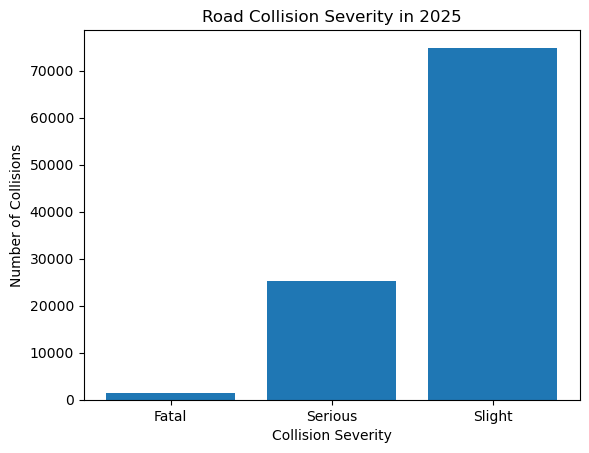

In [15]:
import matplotlib.pyplot as plt

counts = df["collision_severity"].value_counts().sort_index()

plt.bar(["Fatal", "Serious", "Slight"], counts.values)
plt.title("Road Collision Severity in 2025")
plt.xlabel("Collision Severity")
plt.ylabel("Number of Collisions")
plt.show()

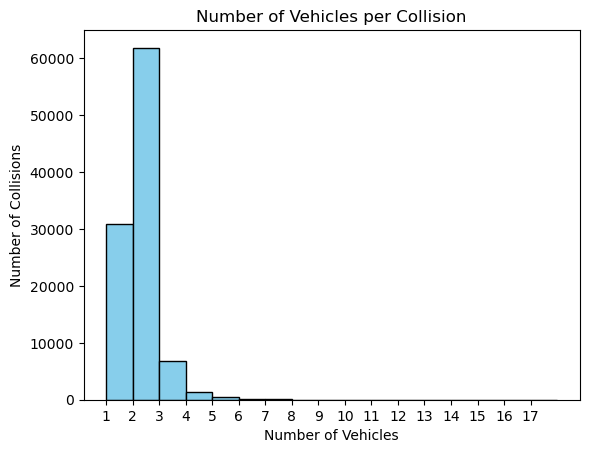

In [16]:
plt.hist(df["number_of_vehicles"], bins=range(1, 19), color="skyblue", edgecolor="black")
plt.title("Number of Vehicles per Collision")
plt.xlabel("Number of Vehicles")
plt.ylabel("Number of Collisions")
plt.xticks(range(1, 18))
plt.show()

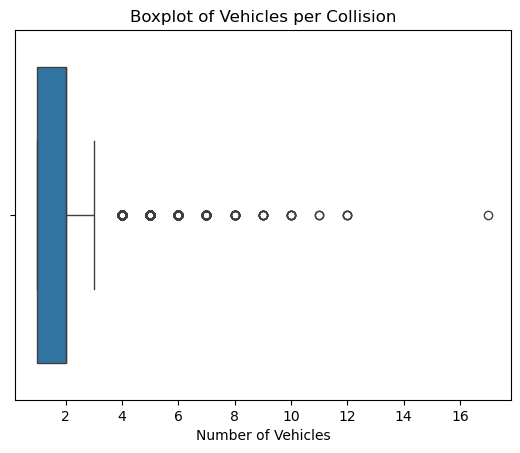

In [17]:
import seaborn as sns

sns.boxplot(x=df["number_of_vehicles"])

plt.title("Boxplot of Vehicles per Collision")
plt.xlabel("Number of Vehicles")
plt.show()

In [18]:
q1 = df["number_of_vehicles"].quantile(0.25)
q3 = df["number_of_vehicles"].quantile(0.75)

iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Upper limit:", upper_limit)

Q1: 1.0
Q3: 2.0
IQR: 1.0
Upper limit: 3.5


In [19]:
outliers = df[df["number_of_vehicles"] > upper_limit]

print("Number of outliers:", len(outliers))
print("Percentage:", len(outliers) / len(df) * 100)

Number of outliers: 1939
Percentage: 1.9098744151686775



## 3. Binomial Distribution

What is the probability that exactly 3 out of 10 randomly selected
collisions are fatal or serious?

Fatal and serious collisions are treated as success, while slight
collisions are treated as failure.

In [20]:
severe = df["collision_severity"] < 3

p = severe.mean()

print("Probability:", p)
print("Percentage:", p * 100)

Probability: 0.2624378231962571
Percentage: 26.24378231962571


In [21]:
from scipy.stats import binom

n = 10
k = 3

probability = binom.pmf(k, n, p)

print("Probability:", probability)
print("Percentage:", probability * 100)

Probability: 0.25754373418061927
Percentage: 25.754373418061927


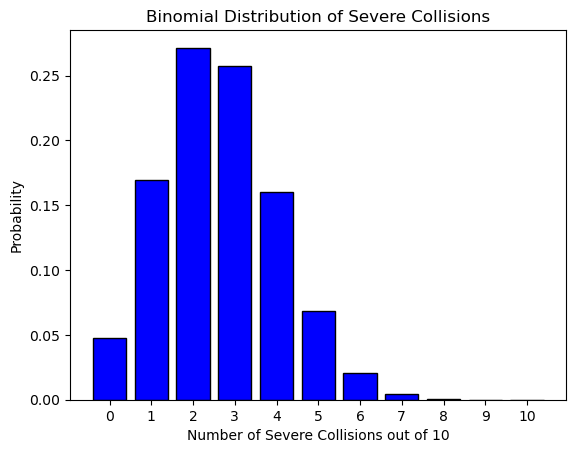

In [22]:
import numpy as np

k_values = np.arange(0, n + 1)
probabilities = binom.pmf(k_values, n, p)

plt.bar(k_values, probabilities, color="blue", edgecolor="black")
plt.title("Binomial Distribution of Severe Collisions")
plt.xlabel("Number of Severe Collisions out of 10")
plt.ylabel("Probability")
plt.xticks(k_values)
plt.show()

In [23]:
df["date"] = pd.to_datetime(df["date"], format="%d/%m/%Y")
print(df["date"].head())

0   2025-02-04
1   2025-05-07
2   2025-11-27
3   2025-05-15
4   2025-12-08
Name: date, dtype: datetime64[ns]


In [24]:
daily_counts = df.groupby("date").size()
print(daily_counts.head())
print("Number of days:", len(daily_counts))

date
2025-01-01    152
2025-01-02    247
2025-01-03    275
2025-01-04    190
2025-01-05    141
dtype: int64
Number of days: 365


In [25]:
print("Number of days:", len(daily_counts))
print("Mean:", daily_counts.mean())
print("Variance:", daily_counts.var())

Number of days: 365
Mean: 278.1506849315069
Variance: 2753.0678910130964


## 4. Poisson Distribution

Daily Road Collisions in Cleveland

In [26]:
region = df[df["police_force"] == 17]
print("Number of collisions:", len(region))

Number of collisions: 488


In [27]:
lambda_rate = len(region) / 365
print("Average collisions per day:", lambda_rate)

Average collisions per day: 1.336986301369863


In [28]:
from scipy.stats import poisson

k = 2
poisson_probability = poisson.pmf(k, lambda_rate)

print("Probability:", poisson_probability)
print("Percentage:", poisson_probability * 100)

Probability: 0.2347351603969204
Percentage: 23.47351603969204


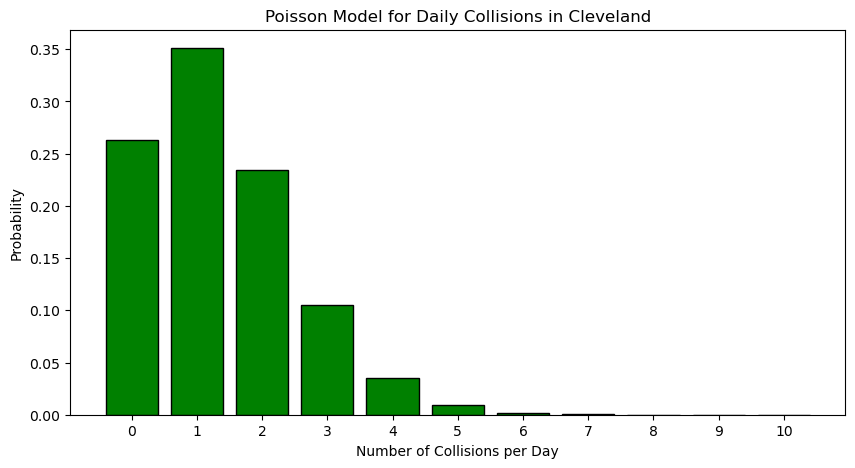

In [29]:
k_values = np.arange(0, 11)
poisson_probabilities = poisson.pmf(k_values, lambda_rate)

plt.figure(figsize=(10, 5))
plt.bar(k_values, poisson_probabilities, color="green", edgecolor="black")
plt.title("Poisson Model for Daily Collisions in Cleveland")
plt.xlabel("Number of Collisions per Day")
plt.ylabel("Probability")
plt.xticks(k_values)
plt.show()

## 5. Normal Distribution

### 5.1 Descriptive Statistics

In [30]:
daily_counts.describe()

count    365.000000
mean     278.150685
std       52.469685
min      120.000000
25%      243.000000
50%      279.000000
75%      311.000000
max      412.000000
dtype: float64

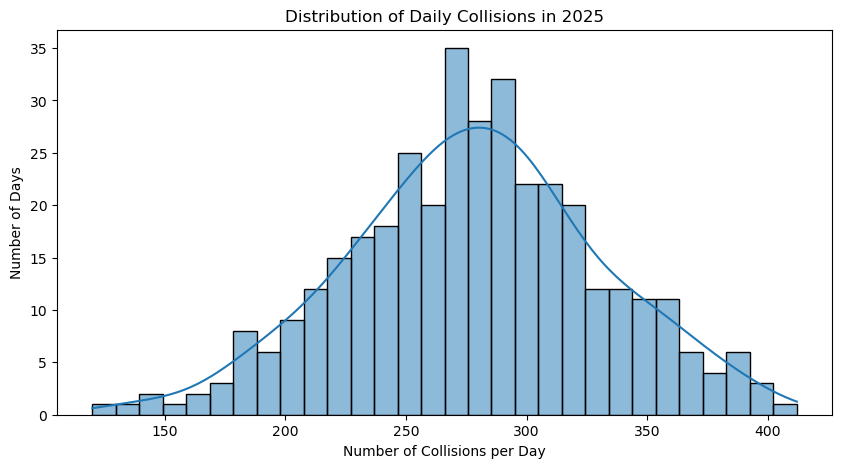

In [31]:
plt.figure(figsize=(10, 5))
sns.histplot(daily_counts, bins=30, kde=True)

plt.title("Distribution of Daily Collisions in 2025")
plt.xlabel("Number of Collisions per Day")
plt.ylabel("Number of Days")
plt.show()

In [32]:
from scipy.stats import skew
print("Skewness:", skew(daily_counts))

Skewness: -0.08772265301095754


In [33]:
from scipy.stats import kurtosis
print("Excess kurtosis:", kurtosis(daily_counts))

Excess kurtosis: -0.07569024057299156


In [34]:
mean = daily_counts.mean()
std = daily_counts.std()

print("Mean:", mean)
print("Standard deviation:", std)

Mean: 278.1506849315069
Standard deviation: 52.46968544800985


In [35]:
from scipy.stats import norm
probability = 1 - norm.cdf(300.5, loc=mean, scale=std)
print("Percentage:", probability * 100)

Percentage: 33.507316390563616


In [36]:
actual_percentage = (daily_counts > 300).mean() * 100

print("Actual percentage:", actual_percentage)

Actual percentage: 32.602739726027394


## 6. Binomial and Normal Approximation

### 6.1 Simulation with 100 Trials

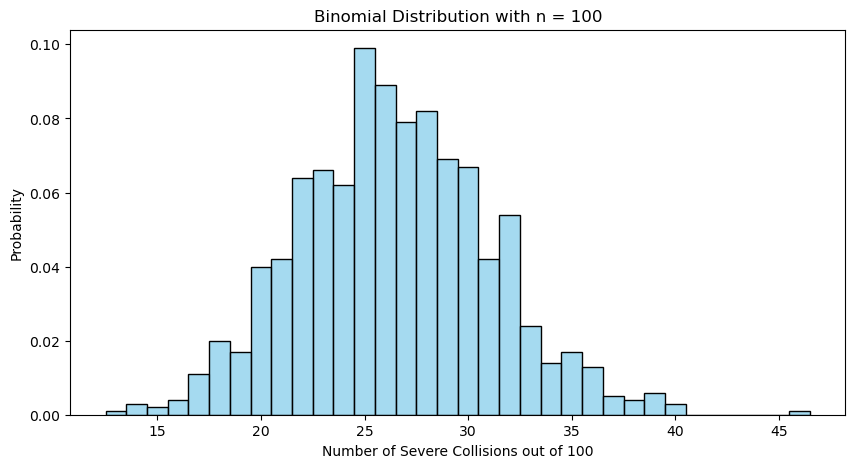

In [37]:
n_large = 100
p = severe.mean()

binomial_data = np.random.binomial(n_large, p, 1000)

plt.figure(figsize=(10, 5))
sns.histplot(binomial_data, discrete=True, stat="probability", color="skyblue")
plt.title("Binomial Distribution with n = 100")
plt.xlabel("Number of Severe Collisions out of 100")
plt.ylabel("Probability")
plt.show()

In [38]:
binomial_mean = n_large * p
binomial_std = np.sqrt(n_large * p * (1 - p))

print("Mean:", binomial_mean)
print("Standard deviation:", binomial_std)

Mean: 26.24378231962571
Standard deviation: 4.39959330111622


### 6.2 Comparing the Probabilities

In [39]:
binomial_result = binom.cdf(30, n_large, p)
normal_result = norm.cdf(30.5, loc=binomial_mean, scale=binomial_std)

print("Binomial percentage:", binomial_result * 100)
print("Normal percentage:", normal_result * 100)

Binomial percentage: 83.37163250466412
Normal percentage: 83.33308481422331


In [40]:
region_counts = region.groupby("date").size()

days_with_two = (region_counts == 2).sum()
actual_percentage = days_with_two / 365 * 100

print("Days with exactly 2 collisions:", days_with_two)
print("Actual percentage:", actual_percentage)

Days with exactly 2 collisions: 81
Actual percentage: 22.19178082191781


## 7. Collisions by Day of the Week

In [41]:
day_counts = df["day_of_week"].value_counts().sort_index()
print(day_counts)

day_of_week
1    11197
2    14309
3    14880
4    15369
5    15304
6    16811
7    13655
Name: count, dtype: int64


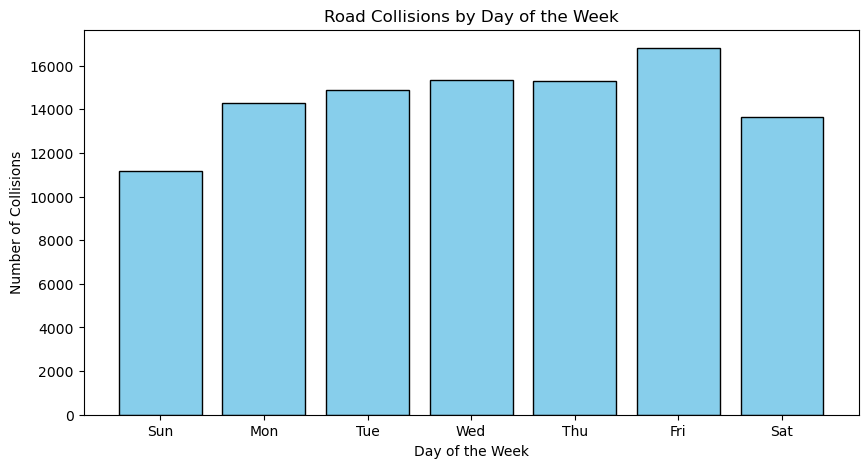

In [42]:
days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]

plt.figure(figsize=(10, 5))
plt.bar(days, day_counts.values, color="skyblue", edgecolor="black")
plt.title("Road Collisions by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Collisions")
plt.show()

In [43]:
day_percentages = day_counts / len(df) * 100
print(day_percentages)

day_of_week
1    11.028811
2    14.094066
3    14.656489
4    15.138143
5    15.074120
6    16.558483
7    13.449889
Name: count, dtype: float64


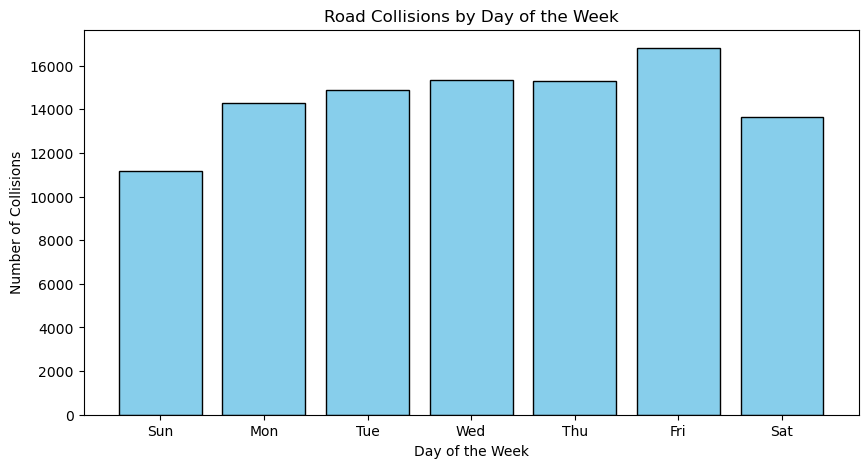

In [44]:
days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]

plt.figure(figsize=(10, 5))
plt.bar(days, day_counts.values, color="skyblue", edgecolor="black")
plt.title("Road Collisions by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Collisions")
plt.show()